# 07 - Comparison & Analysis

Brings every model into one place. It follows the **standardised benchmark protocol** of notebooks 03-06:

> tune on validation (Optuna, TPE seed 42, 25 trials) -> read `E_best` -> refit on **train + validation** for
> exactly `E_best` epochs with **5 seeds** (1, 7, 13, 2024, 99) -> score once on test -> log a **mean row** and a
> **`<model> (std)` row** to `results.csv`.

This notebook does **not** re-tune. The four **base** models (Markov, FPMC-user, GRU4Rec-no-side, SASRec-no-side) are read
from `results.csv`, `results/tuning/*.json` and `results/tuning/*-per-seed.csv`. The **ablation variants** are *not*
tuned either: section 2 re-runs them (5 seeds) with the **base model's selected hyper-parameters and `E_best`**, so each
ablation changes exactly one thing. Their results are cached in `results/ablation_base_hparams/`.
The analyses that need **ranked lists** (slices, bootstrap) re-fit one seed.

**Structure**
1. setup + **sanity peg** (Popularity reproduces ~0.053),
2. **ablations** - every variant of each of the 4 algorithms compared, with explanations; run with the base models'
   hyper-parameters (no separate tuning),
3. **headline benchmark** - the 4 base models side by side,
4. ranked lists for the 4 base models (one re-fitted seed each),
5. sliced by **trip length**,
6. sliced by **destination popularity**,
7. **efficiency** (#params, time per epoch),
8. **bootstrap** confidence intervals over test trips,
9. **final discussion & key takeaways**.

From section 3 onward, "the model" for each algorithm always means its **base variant** (`HEADLINE`, section 2.4).

In [6]:
import os, sys, json, glob, pickle, warnings
def find_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    for _ in range(6):
        if os.path.exists(os.path.join(d, 'src', 'preprocessing.py')):
            return d
        d = os.path.dirname(d)
    return os.path.abspath(os.path.join(os.getcwd(), '..'))
ROOT = find_root(); sys.path.insert(0, ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
try:
    import torch
    if torch.cuda.is_available():
        DEVICE = 'cuda'
    elif getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available():
        DEVICE = 'mps'          # Apple Silicon
    else:
        DEVICE = 'cpu'
except ImportError:
    DEVICE = 'cpu'

from src.preprocessing import load_processed, preprocess, merge_train_val
from src.evaluate import (evaluate, evaluate_sliced, evaluate_popularity,
                          city_frequency, append_result, load_results,
                          bootstrap_ci, paired_bootstrap_diff)
from src.models.gru4rec import FINAL_SEEDS
from src.models import markov as M_markov, fpmc as M_fpmc, gru4rec as M_gru, sasrec as M_sasrec

RESULTS    = os.path.join(ROOT, 'results.csv')
TUNING_DIR = os.path.join(ROOT, 'results', 'tuning')
CACHE_PATH = os.path.join(ROOT, 'data', 'processed', 'ranked_rep.pkl')   # git-ignored (data/processed/)
SEEDS      = list(FINAL_SEEDS)          # the 5 final-fit seeds (n=5 behind every (std) row)
REP_SEED   = SEEDS[0]                   # seed re-fitted to get ranked lists for slicing / bootstrap

try:
    data = load_processed(os.path.join(ROOT, 'data', 'processed'))
except FileNotFoundError:
    data = preprocess(data_dir=os.path.join(ROOT, 'data'))
print('device:', DEVICE, '| loaded:', data['meta'])
if data['meta'].get('sample_n_trips') is not None:
    print('WARNING: processed data was built on a subsample (sample_n_trips=%r). Rebuild on the full '
          'dataset before trusting any number below.' % data['meta']['sample_n_trips'])

targets = [t['target_city'] for t in data['test']]

device: cuda | loaded: {'min_trip_len': 4, 'val_frac': 0.1, 'sample_n_trips': None, 'seed': 42, 'n_train_trips': 190737, 'n_valid_trips': 21187, 'n_test_trips': 70662, 'n_cities': 39903, 'n_users': 200153, 'n_personas': 15, 'n_test_targets_unseen': 0}


## 1. Sanity peg -- does the scorer reproduce the known Popularity number?

Popularity (every trip gets the same global-frequency ranking, no context at all) has a known reference:
`Accuracy@4` (= HR@4) should land close to the repo demo's ~0.053. If it does, that is independent evidence that
`evaluate.py` scores correctly - and every other number depends on that, so we check it first.

Popularity is not produced by any model notebook, so it is computed here and logged to `results.csv` (once -
the cell skips the write if the row is already there). It is deterministic, so it has no `(std)` row.

In [ ]:
pop_metrics = evaluate_popularity(data)
print('Popularity metrics:', {k: round(v, 4) if isinstance(v, float) else v for k, v in pop_metrics.items()})

ref = 0.053
diff = abs(pop_metrics['Accuracy@4'] - ref)
if diff > 0.02:
    print(f"\nWARNING: Accuracy@4={pop_metrics['Accuracy@4']:.4f} is more than 0.02 from the ~{ref} reference. "
          f"Check this is the full dataset and that the preprocessing filters match the reference implementation.")
else:
    print(f"\nOK -- Accuracy@4={pop_metrics['Accuracy@4']:.4f} is within 0.02 of the ~{ref} reference "
          f"(|diff|={diff:.4f}). Scorer looks correct.")

if 'Popularity' not in pd.read_csv(RESULTS)['model'].values:
    append_result(RESULTS, 'Popularity', pop_metrics)
    print('logged Popularity to results.csv')

Popularity metrics: {'HR@1': 0.0177, 'NDCG@1': 0.0177, 'Accuracy@4': 0.0425, 'HR@5': 0.0523, 'NDCG@5': 0.0341, 'HR@10': 0.1021, 'NDCG@10': 0.0503, 'MRR': 0.035, 'n_trips': 70662}

OK -- Accuracy@4=0.0425 is within 0.02 of the ~0.053 reference (|diff|=0.0105). Scorer looks correct.


## 2. Ablations -- every variant of every algorithm

Each of the four algorithms has one base model and one or more ablation variants:

| Algorithm | Base model (tuned) | Ablation variant(s) (not tuned) | Question the ablation asks |
|---|---|---|---|
| **Markov** | `Markov` (Dirichlet **recursion** through lower orders) | `Markov (no recursion)` (highest order only) | does backing off to lower-order contexts matter? |
| **FPMC** | `FPMC-user` (raw `user_id`) | `FPMC-persona` (booker_country x device) | where does personalisation signal live? |
| **GRU4Rec** | `GRU4Rec-no-side` | `GRU4Rec-side` (device, booker country, affiliate; added to the item embedding) | does trip-level context help a recurrent model? |
| **SASRec** | `SASRec-no-side` | `-side-sum` and `-side-concat` | does context help, and is it better summed into or concatenated with the city embedding? |

**No hyper-parameter selection for ablations.** Only the base models are tuned (Optuna, 25 trials, validation
NDCG@10). Each ablation variant is run with *exactly the base model's* `best_params` and `E_best` and the same 5 seeds
(Markov: one deterministic run with the base `max_order` / `mu`). Any difference between a variant and its base is
therefore caused by the ablated component alone, not by a different tuned configuration. The price is that a variant
may be slightly under-tuned for its own architecture - the base model's configuration was optimised for the base.

The base rows come from `results.csv`; the ablation rows are produced by the next cell (cached under
`results/ablation_base_hparams/`, so it only trains once).

In [8]:
means, stds = load_results(RESULTS)          # base models (and Popularity) come from results.csv
METRIC_COLS = ['HR@1', 'HR@5', 'HR@10', 'NDCG@5', 'NDCG@10', 'MRR']

def load_tuning(tag):
    with open(os.path.join(TUNING_DIR, f'{tag}.json')) as f:
        return json.load(f)

# Ablation variants inherit the BASE model's tuned hyper-parameters and E_best. No search is run for them.
ABL_DIR = os.path.join(ROOT, 'results', 'ablation_base_hparams')
os.makedirs(ABL_DIR, exist_ok=True)
ABL_SPECS = {
    'Markov (no recursion)': dict(kind='markov', base='Markov',          recursive=False),
    'FPMC-persona':          dict(kind='fpmc',   base='fpmc-user',       kw=dict(axis='persona')),
    'GRU4Rec-side':          dict(kind='gru',    base='gru4rec-no-side', kw=dict(side_feats=M_gru.SIDE_FEATURES)),
    'SASRec-side-sum':       dict(kind='sasrec', base='sasrec-no-side',  kw=dict(side_feats=M_sasrec.SIDE_FEATURES, side_mode='sum')),
    'SASRec-side-concat':    dict(kind='sasrec', base='sasrec-no-side',  kw=dict(side_feats=M_sasrec.SIDE_FEATURES, side_mode='concat')),
}
FINAL_FN = {'fpmc': M_fpmc.final_fpmc, 'gru': M_gru.final_gru4rec, 'sasrec': M_sasrec.final_sasrec}

def run_ablation(name):
    """Per-seed result table of one ablation variant, using its base model's hyper-parameters. Cached on disk."""
    spec = ABL_SPECS[name]
    path = os.path.join(ABL_DIR, name.replace(' ', '_').replace('(', '').replace(')', '') + '-per-seed.csv')
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0), path
    if spec['kind'] == 'markov':
        base = load_tuning('markov')[spec['base']]
        metrics, _ = M_markov.final_markov(data, base['best_params'], recursive=spec['recursive'])
        df = pd.DataFrame([metrics], index=['deterministic'])
    else:
        base = load_tuning(spec['base'])
        print(f"--- {name}: base config of {spec['base']} (E_best={base['E_best']}), seeds {SEEDS} ---")
        df, _ = FINAL_FN[spec['kind']](data, base['best_params'], epochs=base['E_best'], seeds=SEEDS,
                                       device=DEVICE, **spec['kw'])
    df.to_csv(path)
    return df, path

abl_per_seed = {}
for name in ABL_SPECS:
    abl_per_seed[name], _ = run_ablation(name)
    df = abl_per_seed[name]
    for c in METRIC_COLS:                       # the ablation rows replace whatever results.csv had for them
        means.loc[name, c] = df[c].mean()
        stds.loc[name, c] = df[c].std() if len(df) > 1 else np.nan
print('ablation variants run with the base models\' hyper-parameters:', list(abl_per_seed))

--- SASRec-side-sum: base config of sasrec-no-side (E_best=5), seeds [1, 7, 13, 2024, 99] ---

SASRec (sum) - 5 seeds
                    mean     std
HR@1        2.813000e-01  0.0008
NDCG@1      2.813000e-01  0.0008
Accuracy@4  5.050000e-01  0.0046
HR@5        5.423000e-01  0.0031
NDCG@5      4.183000e-01  0.0018
HR@10       6.588000e-01  0.0023
NDCG@10     4.561000e-01  0.0014
MRR         3.929000e-01  0.0012
n_trips     7.066200e+04  0.0000
train_secs  2.583600e+02  0.9813
n_params    1.263949e+07  0.0000
--- SASRec-side-concat: base config of sasrec-no-side (E_best=5), seeds [1, 7, 13, 2024, 99] ---

SASRec (concat) - 5 seeds
                    mean     std
HR@1        2.786000e-01  0.0014
NDCG@1      2.786000e-01  0.0014
Accuracy@4  4.848000e-01  0.0020
HR@5        5.201000e-01  0.0031
NDCG@5      4.057000e-01  0.0018
HR@10       6.329000e-01  0.0020
NDCG@10     4.422000e-01  0.0015
MRR         3.829000e-01  0.0014
n_trips     7.066200e+04  0.0000
train_secs  2.582200e+02  0.5215

In [9]:
FAMILIES = {
    'Markov':  ['Markov', 'Markov (no recursion)'],
    'FPMC':    ['FPMC-persona', 'FPMC-user'],
    'GRU4Rec': ['GRU4Rec-no-side', 'GRU4Rec-side'],
    'SASRec':  ['SASRec-no-side', 'SASRec-side-sum', 'SASRec-side-concat'],
}
TITLES = {'Markov':  'Markov (Dirichlet) [Deterministic]',
          'FPMC':    'FPMC (Personalised Transitions)',
          'GRU4Rec': 'GRU4Rec (Recurrent Session)',
          'SASRec':  'SASRec (Self-Attention)'}
DETERMINISTIC = {'Markov', 'Markov (no recursion)', 'Popularity'}
missing = [m for fam in FAMILIES.values() for m in fam if m not in means.index]
if missing:
    print('WARNING: not available:', missing)

def std_of(model, col):
    if model in DETERMINISTIC: return np.nan
    return stds.loc[model, col] if model in stds.index else np.nan

def fmt(model, col):
    m, s = means.loc[model, col], std_of(model, col)
    return f"{m:.4f}" if pd.isna(s) else f"{m:.4f} +/- {s:.4f}"

def pm_table(models):
    models = [m for m in models if m in means.index]
    return pd.DataFrame({c: [fmt(m, c) for m in models] for c in METRIC_COLS}, index=models)

no_std = [m for fam in FAMILIES.values() for m in fam
          if m in means.index and m not in DETERMINISTIC and pd.isna(std_of(m, 'NDCG@10'))]
print('stochastic variants still missing a (std) row:', no_std or 'none')

for fam, variants in FAMILIES.items():
    print(f'\n--- {fam} ablation ---')
    display(pm_table(variants))

stochastic variants still missing a (std) row: none

--- Markov ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
Markov,0.2335,0.4442,0.5213,0.3456,0.3706,0.3231
Markov (no recursion),0.1238,0.1989,0.2418,0.1639,0.1778,0.1580



--- FPMC ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
FPMC-persona,0.2434 +/- 0.0024,0.4814 +/- 0.0018,0.5961 +/- 0.0023,0.3681 +/- 0.0013,0.4052 +/- 0.0018,0.3459 +/- 0.0018
FPMC-user,0.2345 +/- 0.0009,0.4613 +/- 0.0014,0.5739 +/- 0.0007,0.3532 +/- 0.0007,0.3897 +/- 0.0005,0.3325 +/- 0.0006



--- GRU4Rec ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
GRU4Rec-no-side,0.2524 +/- 0.0018,0.5160 +/- 0.0024,0.6391 +/- 0.0016,0.3896 +/- 0.0019,0.4296 +/- 0.0015,0.3645 +/- 0.0016
GRU4Rec-side,0.2560 +/- 0.0027,0.5208 +/- 0.0022,0.6425 +/- 0.0023,0.3941 +/- 0.0022,0.4336 +/- 0.0022,0.3686 +/- 0.0024



--- SASRec ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
SASRec-no-side,0.2769 +/- 0.0006,0.5360 +/- 0.0017,0.6522 +/- 0.0021,0.4130 +/- 0.0009,0.4507 +/- 0.0010,0.3879 +/- 0.0007
SASRec-side-sum,0.2813 +/- 0.0008,0.5423 +/- 0.0031,0.6588 +/- 0.0023,0.4183 +/- 0.0018,0.4561 +/- 0.0014,0.3929 +/- 0.0012
SASRec-side-concat,0.2786 +/- 0.0014,0.5201 +/- 0.0031,0.6329 +/- 0.0020,0.4057 +/- 0.0018,0.4422 +/- 0.0015,0.3829 +/- 0.0014


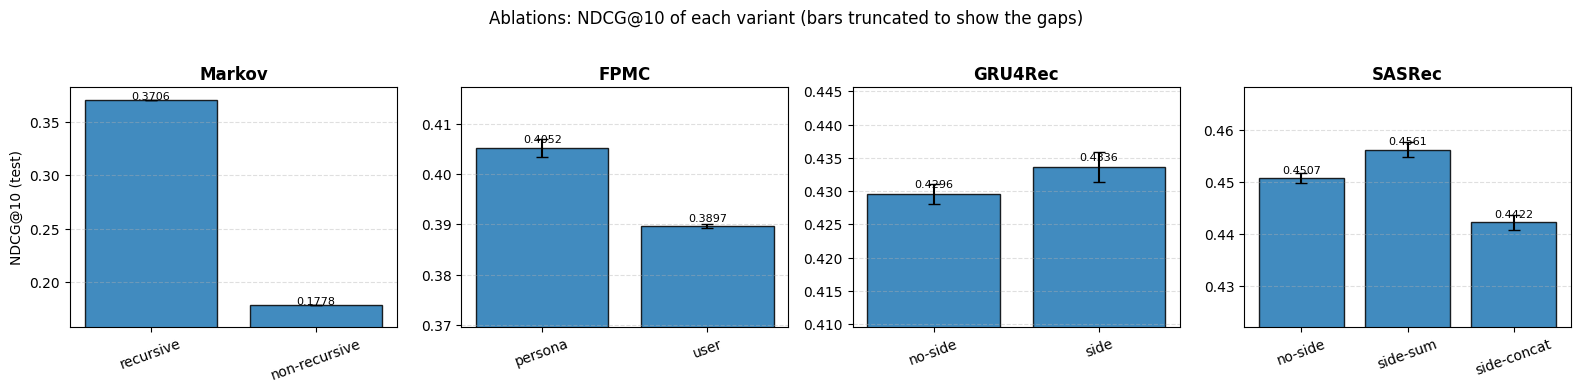

In [10]:
# Ablation figure: NDCG@10 per variant, one panel per algorithm (error bar = seed std where a std row exists)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (fam, variants) in zip(axes, FAMILIES.items()):
    vs = [v for v in variants if v in means.index]
    m = [means.loc[v, 'NDCG@10'] for v in vs]
    s = [0.0 if pd.isna(std_of(v, 'NDCG@10')) else std_of(v, 'NDCG@10') for v in vs]

    ax.bar(range(len(vs)), m, yerr=s, capsize=4, edgecolor='black', alpha=0.85)

    # --- TARGETED LABEL LOGIC ---
    if fam == 'Markov':
        clean_labels = []
        for v in vs:
            modifier = v.replace(fam + '-', '').replace(fam, '').lower()
            if 'no' in modifier or 'false' in modifier:
                clean_labels.append('non-recursive')
            else:
                clean_labels.append('recursive')
    else:
        clean_labels = [v.replace(fam + '-', '').replace(fam, 'recursive') for v in vs]

    ax.set_xticks(range(len(vs)))
    ax.set_xticklabels(clean_labels, rotation=20)
    # ----------------------------

    ax.set_title(fam, fontweight='bold')
    ax.set_ylim(min(m) - 0.02, max(m) + 0.012)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for i, val in enumerate(m):
        ax.text(i, val + 0.001, f'{val:.4f}', ha='center', fontsize=8)

axes[0].set_ylabel('NDCG@10 (test)')
fig.suptitle('Ablations: NDCG@10 of each variant (bars truncated to show the gaps)', y=1.02)
plt.tight_layout()
plt.show()

### 2.1 Configurations used and the validation -> test gap

Base models: what Optuna picked and how many epochs the refit used (`E_best`). Ablation variants: **the same
hyper-parameters and `E_best` as their base** (the `base` column says which), with no search of their own, so the
validation column is the base model's. The test column is each variant's own 5-seed mean. Because validation is
shared within a family, it cannot rank a variant against its base - the test column does that.

In [11]:
TAGS = {'FPMC-user': 'fpmc-user', 'GRU4Rec-no-side': 'gru4rec-no-side', 'SASRec-no-side': 'sasrec-no-side'}   # tuned base models
BASE_OF = {'Markov (no recursion)': 'Markov', 'FPMC-persona': 'FPMC-user', 'GRU4Rec-side': 'GRU4Rec-no-side',
           'SASRec-side-sum': 'SASRec-no-side', 'SASRec-side-concat': 'SASRec-no-side'}

rows = []
for name, tag in TAGS.items():
    if not os.path.exists(os.path.join(TUNING_DIR, f'{tag}.json')):
        continue
    j = load_tuning(tag)
    rows.append({'model': name, 'E_best': j['E_best'], 'val_NDCG@10': j['best_val_NDCG@10'], **j['best_params']})
rows.append({'model': 'Markov', 'E_best': None, 'val_NDCG@10': load_tuning('markov')['Markov']['best_val_NDCG@10'],
             **load_tuning('markov')['Markov']['best_params']})
for name, b in BASE_OF.items():                       # ablations: inherit the base row's hyper-parameters
    r = next(x for x in rows if x['model'] == b)
    rows.append({**r, 'model': name})
cfg_df = pd.DataFrame(rows).set_index('model')
cfg_df.insert(0, 'base', [BASE_OF.get(m, '(tuned)') for m in cfg_df.index])
cfg_df.insert(3, 'test_NDCG@10', [means.loc[m, 'NDCG@10'] if m in means.index else np.nan for m in cfg_df.index])
cfg_df.insert(4, 'val_minus_test', cfg_df['val_NDCG@10'] - cfg_df['test_NDCG@10'])
display(cfg_df.round(4))

,base,E_best,val_NDCG@10,test_NDCG@10,val_minus_test,lr,weight_decay,embed_dim,batch_size,dropout,num_layers,max_len,num_blocks,max_order,mu
model,,,,,,,,,,,,,,,
FPMC-user,(tuned),2.0,0.4172,0.3897,0.0275,0.0007,0.0000,256.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN
GRU4Rec-no-side,(tuned),13.0,0.4316,0.4296,0.0020,0.0013,0.0000,256.0,128.0,0.3592,2.0,30.0,NaN,NaN,NaN
SASRec-no-side,(tuned),5.0,0.4652,0.4507,0.0145,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN
Markov,(tuned),NaN,0.4128,0.3706,0.0422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,41.3831
Markov (no recursion),Markov,NaN,0.4128,0.1778,0.2350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,41.3831
FPMC-persona,FPMC-user,2.0,0.4172,0.4052,0.0120,0.0007,0.0000,256.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN
GRU4Rec-side,GRU4Rec-no-side,13.0,0.4316,0.4336,-0.0020,0.0013,0.0000,256.0,128.0,0.3592,2.0,30.0,NaN,NaN,NaN
SASRec-side-sum,SASRec-no-side,5.0,0.4652,0.4561,0.0091,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN
SASRec-side-concat,SASRec-no-side,5.0,0.4652,0.4422,0.0230,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN


### 2.2 Are the ablation gaps bigger than seed noise?

The 5 seeds differ only in initialisation and batch/negative order, so their std is the **training** noise. For each
pair we compare the gap in mean NDCG@10 with that noise via Welch's t-test from the summary statistics (n = 5 per
model). Base rows use `results.csv`; ablation rows use the fresh 5-seed runs from the cell above. Deterministic models
(Markov) are compared as a one-sample test against a fixed number; pairs missing a std row are listed as skipped.

In [12]:
from math import sqrt
try:
    from scipy import stats as sps
except ImportError:
    sps = None
N_SEEDS = len(SEEDS)

def gap(a, b, col='NDCG@10'):
    ma, mb = means.loc[a, col], means.loc[b, col]
    sa = 0.0 if a in DETERMINISTIC else std_of(a, col)
    sb = 0.0 if b in DETERMINISTIC else std_of(b, col)
    if pd.isna(sa) or pd.isna(sb):
        return dict(A=a, B=b, gap=ma - mb, note='missing std row')
    out = dict(A=a, B=b, gap=ma - mb, std_A=sa, std_B=sb)
    pooled = sqrt((sa**2 + sb**2) / 2)
    out['gap/pooled_std'] = (ma - mb) / pooled if pooled > 0 else np.inf
    if sps is not None and (sa > 0 or sb > 0):
        if a in DETERMINISTIC or b in DETERMINISTIC:      # one-sample t against a fixed value
            s, fixed, x = (sb, ma, mb) if a in DETERMINISTIC else (sa, mb, ma)
            t = (x - fixed) / (s / sqrt(N_SEEDS)); p = 2 * sps.t.sf(abs(t), N_SEEDS - 1)
        else:
            t, p = sps.ttest_ind_from_stats(ma, sa, N_SEEDS, mb, sb, N_SEEDS, equal_var=False)
        out['p_value'] = p
    return out

ABL_PAIRS = [('Markov', 'Markov (no recursion)'),
             ('FPMC-persona', 'FPMC-user'),
             ('GRU4Rec-side', 'GRU4Rec-no-side'),
             ('SASRec-side-sum', 'SASRec-no-side'),
             ('SASRec-side-concat', 'SASRec-no-side'),
             ('SASRec-side-sum', 'SASRec-side-concat')]
abl_gap = pd.DataFrame([gap(a, b) for a, b in ABL_PAIRS if a in means.index and b in means.index])
display(abl_gap.round(4))
if 'note' in abl_gap:
    sk = abl_gap[abl_gap['note'].notna()]
    if len(sk):
        print('Skipped (no std row yet):', [f"{r.A} vs {r.B}" for r in sk.itertuples()])

,A,B,gap,std_A,std_B,gap/pooled_std,p_value
0,Markov,Markov (no recursion),0.1928,0.0000,0.0000,inf,NaN
1,FPMC-persona,FPMC-user,0.0156,0.0018,0.0005,11.9822,0.0000
2,GRU4Rec-side,GRU4Rec-no-side,0.0040,0.0022,0.0015,2.0821,0.0133
3,SASRec-side-sum,SASRec-no-side,0.0054,0.0014,0.0010,4.3882,0.0002
4,SASRec-side-concat,SASRec-no-side,-0.0085,0.0015,0.0010,-6.7501,0.0000
5,SASRec-side-sum,SASRec-side-concat,0.0139,0.0014,0.0015,9.4990,0.0000


,n_seeds,csv_mean,results.csv_mean,csv_std,results.csv_std,min,max
model,,,,,,,
FPMC-user,5,0.38967,0.38967,0.00049,0.00049,0.38910,0.39025
GRU4Rec-no-side,5,0.42962,0.42962,0.00150,0.00150,0.42790,0.43189
SASRec-no-side,5,0.45068,0.45068,0.00098,0.00098,0.44908,0.45168
FPMC-persona,5,0.40522,0.40522,0.00177,0.00177,0.40268,0.40730
GRU4Rec-side,5,0.43359,0.43359,0.00224,0.00224,0.43027,0.43616
SASRec-side-sum,5,0.45611,0.45611,0.00145,0.00145,0.45384,0.45735
SASRec-side-concat,5,0.44221,0.44221,0.00148,0.00148,0.44071,0.44416


mean rows consistent with per-seed CSVs
no per-seed CSV for: ['Markov (no recursion)']


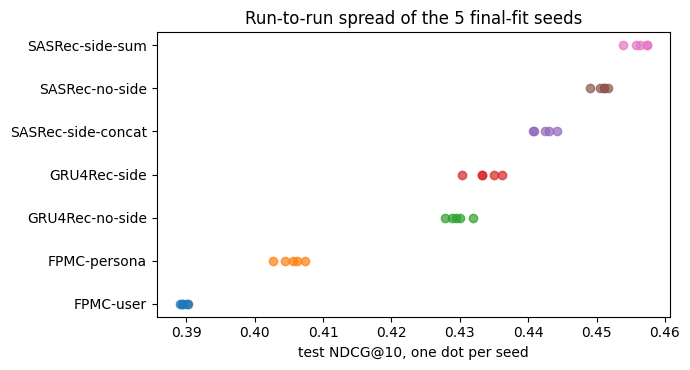

In [13]:
# Per-seed spread behind the (std) rows, where per-seed CSVs exist, + a check that each mean row in results.csv
# really is the mean of its 5 per-seed rows.
per_seed = {}
for name, tag in TAGS.items():                          # tuned base models: per-seed CSVs from the tuning notebooks
    p = os.path.join(TUNING_DIR, f'{tag}-per-seed.csv')
    if os.path.exists(p):
        per_seed[name] = pd.read_csv(p, index_col=0)
for name, df in abl_per_seed.items():                   # ablations: re-run with base hyper-parameters (cell above)
    if len(df) > 1:
        per_seed[name] = df

chk = [{'model': n, 'n_seeds': len(df), 'csv_mean': df['NDCG@10'].mean(), 'results.csv_mean': means.loc[n, 'NDCG@10'],
        'csv_std': df['NDCG@10'].std(), 'results.csv_std': std_of(n, 'NDCG@10'),
        'min': df['NDCG@10'].min(), 'max': df['NDCG@10'].max()} for n, df in per_seed.items()]
chk_df = pd.DataFrame(chk).set_index('model')
display(chk_df.round(5))
bad = chk_df[(chk_df['csv_mean'] - chk_df['results.csv_mean']).abs() > 1e-6]
print('mean rows consistent with per-seed CSVs' if bad.empty else f'MISMATCH between results.csv and per-seed CSV for: {list(bad.index)}')
print('no per-seed CSV for:', [m for m in list(TAGS) + list(ABL_SPECS) if m not in per_seed])

if per_seed:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    names = sorted(per_seed, key=lambda n: per_seed[n]['NDCG@10'].mean())
    for i, n in enumerate(names):
        v = per_seed[n]['NDCG@10'].values
        ax.scatter(v, [i] * len(v), alpha=0.7)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel('test NDCG@10, one dot per seed'); ax.set_title('Run-to-run spread of the 5 final-fit seeds')
    plt.tight_layout(); plt.show()

### 2.3 What the ablations show

*(All ablation numbers come from the re-runs with the base models' hyper-parameters; read the actual gaps and
p-values from the tables and the printout below. This text only describes what each ablation tests and how to read it.)*

**Why this design.** An ablation is only interpretable if the *only* difference is the ablated component. Earlier,
each variant was tuned separately and landed on different configurations (e.g. GRU4Rec-side on 1 layer / `E_best` 4,
GRU4Rec-no-side on 2 layers / `E_best` 13), which mixes the component's effect with a different architecture. With
the base hyper-parameters held fixed, the gap is attributable to the component. The caveat is the reverse: the
base configuration was optimised for the base model, so a variant that needs a different learning rate or depth is
at a small disadvantage. A variant that still wins is therefore a fairly strong result; a variant that loses may
only be under-tuned.

**Markov - recursion.** `Markov` backs off from order 3 through lower orders; `Markov (no recursion)` here uses the
*same* order 3 and mu, but jumps straight from the top order to the unigram when a context is unseen. So this
isolates back-off at a fixed order. A no-recursion model that was tuned alone would pick a much shorter order
(its search chose order 1 earlier); at order 3 it is expected to suffer on every unseen context, which is
exactly the failure that recursion exists to fix.

**FPMC - user vs persona.** Almost every `user_id` appears in a single trip, so a per-user factor learned in
training is rarely reused and test users are effectively cold-start. The persona (booker country x device) recurs across
many trips, so its factor can be learned and transferred. Note the persona variant here inherits the *user*
model's `E_best` (short, because the user table memorises quickly), which may stop the persona variant before it has
fully trained.

**GRU4Rec - side features.** In `GRU4Rec-side` each side-feature embedding (device, booker country, affiliate) is
**added** to the scaled item embedding at every step, before the GRU. There is no concat option in the GRU4Rec code.

**SASRec - side-sum vs side-concat.** `side-sum` adds the side embeddings to the city embedding (same mechanism as
GRU4Rec-side); `side-concat` concatenates a half-width side embedding and projects it back. Both use the SASRec
no-side hyper-parameters and `E_best`.

**How to read the gaps.** Compare each gap with the seed std (`gap/pooled_std`) and the Welch p-value in 2.2: a gap of
a few seed-stds is detectable, a gap inside the seed spread is not. Printout of the measured gaps:

In [14]:
for r in abl_gap.itertuples():
    p = getattr(r, 'p_value', np.nan)
    ptxt = '' if pd.isna(p) else f', Welch p = {p:.3g}'
    verdict = 'A better' if r.gap > 0 else 'B better'
    print(f"  {r.A} vs {r.B}: NDCG@10 gap {r.gap:+.4f}{ptxt} ({verdict}"
          f"{'; significant at 0.05' if (not pd.isna(p)) and p < 0.05 else ''})")

  Markov vs Markov (no recursion): NDCG@10 gap +0.1928 (A better)
  FPMC-persona vs FPMC-user: NDCG@10 gap +0.0156, Welch p = 1.53e-05 (A better; significant at 0.05)
  GRU4Rec-side vs GRU4Rec-no-side: NDCG@10 gap +0.0040, Welch p = 0.0133 (A better; significant at 0.05)
  SASRec-side-sum vs SASRec-no-side: NDCG@10 gap +0.0054, Welch p = 0.000219 (A better; significant at 0.05)
  SASRec-side-concat vs SASRec-no-side: NDCG@10 gap -0.0085, Welch p = 1.45e-05 (B better; significant at 0.05)
  SASRec-side-sum vs SASRec-side-concat: NDCG@10 gap +0.0139, Welch p = 3.83e-07 (A better; significant at 0.05)


### 2.4 Selecting the Headline model of each algorithm

In [15]:
# Fixed headline models (chosen by design: the plain/base variant of each algorithm), not selected by score
HEADLINE = {
    'Markov':  'Markov',
    'FPMC':    'FPMC-user',
    'GRU4Rec': 'GRU4Rec-no-side',
    'SASRec':  'SASRec-no-side',
}
assert all(v in means.index for v in HEADLINE.values()), 'a selected row is missing from results.csv'

# for reference: how the chosen models compare with the best variant of each algorithm
ref_rows = []
for fam, variants in FAMILIES.items():
    vs = [v for v in variants if v in means.index]
    best_test = max(vs, key=lambda v: means.loc[v, 'NDCG@10'])
    ref_rows.append({'algorithm': fam, 'headline model': HEADLINE[fam],
                     'NDCG@10 (headline)': means.loc[HEADLINE[fam], 'NDCG@10']})
display(pd.DataFrame(ref_rows).set_index('algorithm').round(4))
print('Headline models:', HEADLINE)

,headline model,NDCG@10 (headline)
algorithm,,
Markov,Markov,0.3706
FPMC,FPMC-user,0.3897
GRU4Rec,GRU4Rec-no-side,0.4296
SASRec,SASRec-no-side,0.4507


Headline models: {'Markov': 'Markov', 'FPMC': 'FPMC-user', 'GRU4Rec': 'GRU4Rec-no-side', 'SASRec': 'SASRec-no-side'}


## 3. Headline benchmark -- the four selected models

One entry per algorithm: its best ablation variant from section 2. Stochastic models (FPMC, GRU4Rec, SASRec) are
**mean +/- std over 5 seeds** [1, 7, 13, 2024, 99], each refit on train + validation for `E_best` epochs with
hyper-parameters tuned on validation only; Markov is a deterministic single run. (A model whose std row is not in
`results.csv` yet shows its mean only.) Popularity is excluded from the plot - it is only the sanity floor of
section 1.


FINAL BENCHMARK RESULTS ACROSS ALL 4 MODELS (best ablation variant of each)
(Stochastic models: Mean +/- Std Dev across 5 seeds [1, 7, 13, 2024, 99]; Markov deterministic: 1 run)
                                                     HR@1               HR@5              HR@10             NDCG@5            NDCG@10                MRR
Markov (Dirichlet) [Deterministic]                 0.2335             0.4442             0.5213             0.3456             0.3706             0.3231
FPMC (Personalised Transitions) [user]  0.2345 +/- 0.0009  0.4613 +/- 0.0014  0.5739 +/- 0.0007  0.3532 +/- 0.0007  0.3897 +/- 0.0005  0.3325 +/- 0.0006
GRU4Rec (Recurrent Session) [no-side]   0.2524 +/- 0.0018  0.5160 +/- 0.0024  0.6391 +/- 0.0016  0.3896 +/- 0.0019  0.4296 +/- 0.0015  0.3645 +/- 0.0016
SASRec (Self-Attention) [no-side]       0.2769 +/- 0.0006  0.5360 +/- 0.0017  0.6522 +/- 0.0021  0.4130 +/- 0.0009  0.4507 +/- 0.0010  0.3879 +/- 0.0007


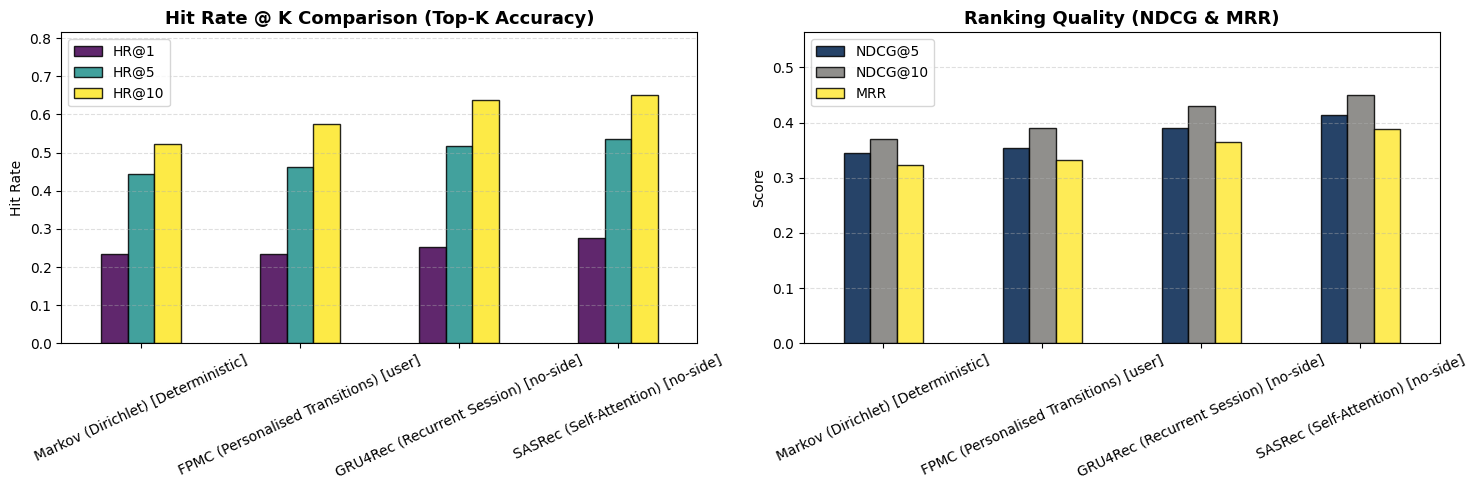

In [ ]:
results_dict, results_disp_dict = {}, {}
for fam, row_name in HEADLINE.items():
    if fam == 'Markov':
        label = TITLES[fam] + ('' if row_name == 'Markov' else ' [no recursion]')
    else:
        label = f"{TITLES[fam]} [{row_name.split('-', 1)[1]}]"      # e.g. 'SASRec (Self-Attention) [side-sum]'
    results_dict[label] = {c: means.loc[row_name, c] for c in METRIC_COLS}
    results_disp_dict[label] = {c: fmt(row_name, c) for c in METRIC_COLS}

df_results = pd.DataFrame(results_dict).T[METRIC_COLS]
df_disp = pd.DataFrame(results_disp_dict).T[METRIC_COLS]

print("\n" + "=" * 100)
print("FINAL BENCHMARK RESULTS ACROSS ALL 4 MODELS (best ablation variant of each)")
print("(Stochastic models: Mean +/- Std Dev across 5 seeds [1, 7, 13, 2024, 99]; Markov deterministic: 1 run)")
print("=" * 100)
print(df_disp.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

hr_cols = ["HR@1", "HR@5", "HR@10"]
df_results[hr_cols].plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="black", alpha=0.85)
axes[0].set_title("Hit Rate @ K Comparison (Top-K Accuracy)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Hit Rate")
axes[0].set_ylim(0, min(1.0, df_results["HR@10"].max() * 1.25))
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].tick_params(axis="x", rotation=25)

rank_cols = ["NDCG@5", "NDCG@10", "MRR"]
df_results[rank_cols].plot(kind="bar", ax=axes[1], colormap="cividis", edgecolor="black", alpha=0.85)
axes[1].set_title("Ranking Quality (NDCG & MRR)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, min(1.0, df_results["NDCG@10"].max() * 1.25))
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
os.makedirs(os.path.join(ROOT, 'results'), exist_ok=True)
plt.savefig(os.path.join(ROOT, 'results', 'benchmark_comparison.png'), dpi=150)
plt.show()

In [ ]:
# Step-by-step gains up the ladder (Markov -> FPMC -> GRU4Rec -> SASRec), and are they bigger than seed noise?
ladder = [HEADLINE[f] for f in ['Markov', 'FPMC', 'GRU4Rec', 'SASRec']]
steps = pd.DataFrame({c: [means.loc[b, c] - means.loc[a, c] for a, b in zip(ladder[:-1], ladder[1:])]
                      for c in ['HR@1', 'HR@10', 'NDCG@10', 'MRR']},
                     index=[f'{a} -> {b}' for a, b in zip(ladder[:-1], ladder[1:])])
print('Gain at each rung of the ladder:')
display(steps.round(4))

lad_gap = pd.DataFrame([gap(b, a) for a, b in zip(ladder[:-1], ladder[1:])] +
                       [gap(ladder[3], ladder[1]), gap(ladder[3], ladder[0])])
display(lad_gap.round(4))
if 'note' in lad_gap and lad_gap['note'].notna().any():
    print('Pairs skipped for want of a (std) row:',
          [f"{r.A} vs {r.B}" for r in lad_gap[lad_gap['note'].notna()].itertuples()])

Gain at each rung of the ladder:


,HR@1,HR@10,NDCG@10,MRR
Markov -> FPMC-user,0.0011,0.0526,0.0191,0.0094
FPMC-user -> GRU4Rec-no-side,0.0179,0.0653,0.0399,0.0319
GRU4Rec-no-side -> SASRec-no-side,0.0245,0.0131,0.0211,0.0234


,A,B,gap,std_A,std_B,gap/pooled_std,p_value
0,FPMC-user,Markov,0.0191,0.0005,0.0000,55.4270,0.0
1,GRU4Rec-no-side,FPMC-user,0.0399,0.0015,0.0005,35.8867,0.0
2,SASRec-no-side,GRU4Rec-no-side,0.0211,0.0010,0.0015,16.6341,0.0
3,SASRec-no-side,FPMC-user,0.0610,0.0010,0.0005,78.7034,0.0
4,SASRec-no-side,Markov,0.0801,0.0010,0.0000,115.2702,0.0


## 4. Ranked lists for the four selected models

Sections 5-8 need each model's **ranked lists**, which `results.csv` does not store. So the four selected models are
re-fitted for **one seed** (`REP_SEED`, the first of the final seeds) using the final-fit recipe: saved tuned
hyper-parameters, `E_best` epochs, train + validation, scored on test. No re-tuning happens. Markov is deterministic
and simply re-fitted.

Predictions are cached in `data/processed/ranked_rep.pkl` (git-ignored, keyed by variant name and seed); delete it to
force a re-fit. Expect seconds for Markov, minutes per neural model on GPU, and the longest for FPMC.

In [ ]:
# only the 4 headline (base) models are re-fitted for ranked lists; ablations are not used from section 3 on
REP_SPECS = {
    'Markov':                dict(kind='markov', key='Markov', recursive=True),
    'FPMC-user':             dict(kind='fpmc', tag='fpmc-user', kw=dict(axis='user')),
    'GRU4Rec-no-side':       dict(kind='gru', tag='gru4rec-no-side', kw=dict(side_feats=())),
    'SASRec-no-side':        dict(kind='sasrec', tag='sasrec-no-side', kw=dict(side_feats=())),
}

def refit_one(name):
    spec = REP_SPECS[name]
    if spec['kind'] == 'markov':
        j = load_tuning('markov')[spec['key']]
        metrics, ranked = M_markov.final_markov(data, j['best_params'], recursive=spec['recursive'])
        return ranked, metrics
    j = load_tuning(spec['tag'])
    final, mod = {'fpmc': (M_fpmc.final_fpmc, M_fpmc), 'gru': (M_gru.final_gru4rec, M_gru),
                  'sasrec': (M_sasrec.final_sasrec, M_sasrec)}[spec['kind']]
    df, models = final(data, j['best_params'], epochs=j['E_best'], seeds=[REP_SEED], device=DEVICE, **spec['kw'])
    if spec['kind'] == 'fpmc':
        ranked = mod.predict_ranked(models[0], data['test'], spec['kw']['axis'], device=DEVICE)
    else:
        ranked = mod.predict_ranked(models[0], data['test'], device=DEVICE)
    return ranked, df.iloc[0].to_dict()

cache = {}
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, 'rb') as f:
        cache = pickle.load(f)
    if cache.get('_seed') != REP_SEED:
        print('cache was built with a different REP_SEED -> ignoring it'); cache = {}

for name in HEADLINE.values():
    if name not in cache:
        print(f'--- re-fitting {name} (seed {REP_SEED}) ---')
        cache[name] = refit_one(name)
        cache['_seed'] = REP_SEED
        os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
        with open(CACHE_PATH, 'wb') as f:
            pickle.dump(cache, f)

# keyed by the selected variant's results.csv name
ranked_rep  = {name: cache[name][0] for name in HEADLINE.values()}
rep_metrics = {name: cache[name][1] for name in HEADLINE.values()}
print('ranked lists ready for:', list(ranked_rep))

--- re-fitting Markov (seed 1) ---
--- re-fitting FPMC-user (seed 1) ---

FPMC (user) - 1 seeds
                    mean  std
HR@1        2.340000e-01  NaN
NDCG@1      2.340000e-01  NaN
Accuracy@4  4.277000e-01  NaN
HR@5        4.617000e-01  NaN
NDCG@5      3.534000e-01  NaN
HR@10       5.742000e-01  NaN
NDCG@10     3.898000e-01  NaN
MRR         3.326000e-01  NaN
n_trips     7.066200e+04  NaN
train_secs  2.635000e+02  NaN
n_params    8.188646e+07  NaN
--- re-fitting GRU4Rec-no-side (seed 1) ---

GRU4Rec (no side) - 1 seeds
                    mean  std
HR@1        2.551000e-01  NaN
NDCG@1      2.551000e-01  NaN
Accuracy@4  4.749000e-01  NaN
HR@5        5.184000e-01  NaN
NDCG@5      3.921000e-01  NaN
HR@10       6.410000e-01  NaN
NDCG@10     4.319000e-01  NaN
MRR         3.669000e-01  NaN
n_trips     7.066200e+04  NaN
train_secs  5.718000e+02  NaN
n_params    1.106790e+07  NaN
--- re-fitting SASRec-no-side (seed 1) ---

SASRec (no side) - 1 seeds
                    mean  std
HR@1      

## 5. Sliced by trip length -- the project's central hypothesis

Does long-range memory (GRU4Rec, SASRec) pay off on **longer** trips, while the simpler models stay competitive on
short ones? Uses the ranked lists from section 4. The slice variable is the number of **visible** cities in the test
trip (the masked last city is not counted); the shortest possible prefix is 3, since test trips have >= 4 stops.
Group sizes are printed - a small bucket is noisy.

test trips per bucket: {'<=3': 36237, '4-5': 22786, '6+': 11639}


,<=3,4-5,6+
model,,,
Markov,0.3563,0.3833,0.3903
FPMC-user,0.3716,0.4029,0.4212
GRU4Rec-no-side,0.4151,0.4414,0.4657
SASRec-no-side,0.4320,0.4586,0.4804


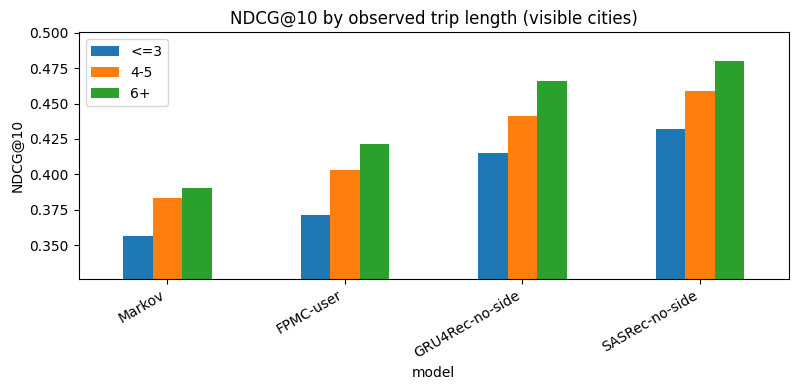

NDCG@10 minus Markov, per length bucket (does the advantage grow with length?):


,<=3,4-5,6+
model,,,
FPMC-user,0.0153,0.0196,0.0309
GRU4Rec-no-side,0.0588,0.0581,0.0753
SASRec-no-side,0.0757,0.0753,0.0901


In [ ]:
def length_group(t):
    n = len(t['cities'])
    return '<=3' if n <= 3 else ('4-5' if n <= 5 else '6+')

LEN_ORDER = ['<=3', '4-5', '6+']
length_groups = [length_group(t) for t in data['test']]
print('test trips per bucket:', pd.Series(length_groups).value_counts().reindex(LEN_ORDER).to_dict())

length_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, length_groups)
    length_rows.append({'model': name, **{g: sl[g]['NDCG@10'] for g in LEN_ORDER if g in sl}})
length_df = pd.DataFrame(length_rows).set_index('model')
display(length_df.round(4))

ax = length_df.plot.bar(figsize=(8, 4))
ax.set_ylim(max(0, length_df.values.min() - 0.03), length_df.values.max() + 0.02)
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by observed trip length (visible cities)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

mk = HEADLINE['Markov']
adv = length_df.drop(index=mk).sub(length_df.loc[mk], axis=1)
print(f'NDCG@10 minus {mk}, per length bucket (does the advantage grow with length?):')
display(adv.round(4))


1. More Context Equals Better Predictions for All Models

Notice how every single model's scores (and the height of the bars) increase as you move from blue (<=3) to orange (4-5) to green (6+).
• For example, SASRec-no-side jumps from 0.4320 to 0.4804.
• The Reason: More data provides a stronger signal. The longer a traveler's sequence is, the more hints the model has to deduce their travel patterns, intentions, and final destination.

2. The Model Complexity Ladder Holds Across All Lengths

No matter how short or long the trip is, the ranking order of the models remains completely unchanged: Markov < FPMC-persona < GRU4Rec-no-side < SASRec-no-side. This proves that deep learning models don't just win on massive sequences—they systematically outperform simpler models even when given very short histories of 3 or fewer cities.

3. Deep Learning’s Advantage Dynamically Grows on Long Trips

The bottom table subtracts the basic Markov score from the advanced models to see if sophisticated architectures pull further ahead when given more data.
• FPMC-user steadily scales its advantage (0.0153 -> 0.0309). Having a longer sequence gives it more opportunities to inject personalized user preferences over standard, unpersonalized city transitions.
• SASRec-no-side achieves its single largest competitive advantage on long trips (+0.0901 in the 6+ bucket). This proves that the Self-Attention mechanism thrives on long-range dependencies. Unlike standard models that get confused or forget early stops, SASRec effectively sifts through long trip histories to pinpoint the most relevant cities.

,train examples,test trips,train share,test share
1,211924,2172,0.246,0.031
2,206750,4862,0.240,0.069
3,188870,29203,0.219,0.413
4,102847,14717,0.119,0.208
5,59362,8069,0.069,0.114
6,35414,4706,0.041,0.067
7,21344,2649,0.025,0.037
8,13099,1671,0.015,0.024
9,8275,969,0.010,0.014
10,5160,629,0.006,0.009


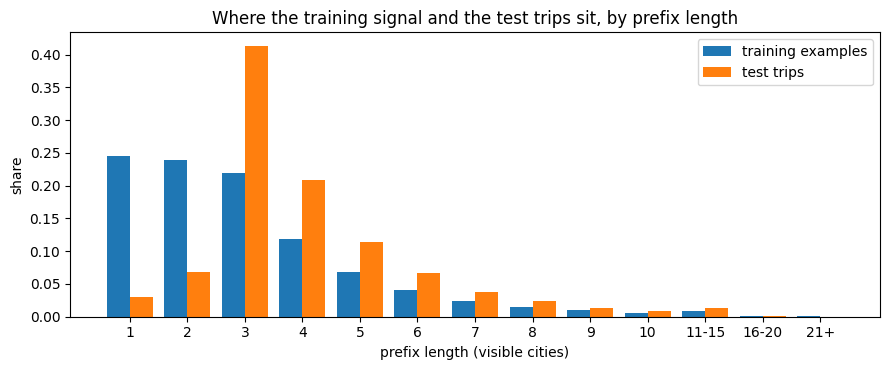

train examples with prefix <=3: 70.4% | 4-5: 18.8% | 6+: 10.8%


In [ ]:
# How much training signal exists at each prefix length? Every (prefix -> next city) pair in a training trip is one
# example, so a trip of n stops contributes one example per prefix length 1..n-1.
from collections import Counter
trips_for_training = merge_train_val(data)['train']          # what the final fits actually trained on
ex_by_prefix = Counter()
for t in trips_for_training:
    for l in range(1, len(t['cities'])):
        ex_by_prefix[l] += 1
test_by_prefix = Counter(len(t['cities']) for t in data['test'])

def bucket(n):
    return str(n) if n <= 10 else ('11-15' if n <= 15 else ('16-20' if n <= 20 else '21+'))
B_ORDER = [str(i) for i in range(1, 11)] + ['11-15', '16-20', '21+']
tr = Counter(); te = Counter()
for n, c in ex_by_prefix.items(): tr[bucket(n)] += c
for n, c in test_by_prefix.items(): te[bucket(n)] += c
dist = pd.DataFrame({'train examples': [tr[b] for b in B_ORDER], 'test trips': [te[b] for b in B_ORDER]}, index=B_ORDER)
dist['train share'] = dist['train examples'] / dist['train examples'].sum()
dist['test share'] = dist['test trips'] / dist['test trips'].sum()
display(dist.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(B_ORDER)); w = 0.4
ax.bar(x - w/2, dist['train share'], w, label='training examples')
ax.bar(x + w/2, dist['test share'], w, label='test trips')
ax.set_xticks(x); ax.set_xticklabels(B_ORDER)
ax.set_xlabel('prefix length (visible cities)'); ax.set_ylabel('share'); ax.legend()
ax.set_title('Where the training signal and the test trips sit, by prefix length')
plt.tight_layout(); plt.show()

g = lambda ks: sum(v for k, v in ex_by_prefix.items() if k in ks) / sum(ex_by_prefix.values())
print(f"train examples with prefix <=3: {g(range(1,4)):.1%} | 4-5: {g([4,5]):.1%} | 6+: {g(range(6,999)):.1%}")


1. Training is Overwhelmed by Minimal Context (Blue Bars)

*  The Data: The blue bars are highly concentrated at prefix lengths 1, 2, and 3.
*  The Meaning: As the text shows, 70.4% of your entire training data forces the model to guess the next city using a history of 3 or fewer visible cities. Because long trips are broken down step-by-step starting from the very first city, the training set naturally creates a massive amount of these short-history examples.

2. Testing Grates Closely on Medium Context (Orange Bars)

*  The Data: The orange bars show almost zero presence at lengths 1 and 2, but explode into a massive peak at length 3 (accounting for over 40% of all test cases) and taper down through lengths 4 and 5.
*  The Meaning: In your actual evaluation, you almost never test the model on its ability to guess a destination from just 1 or 2 cities. The test set is heavily weighted toward evaluating scenarios where the traveler has already visited 3, 4, or 5 cities.

3. The Structural Takeaway (Connecting the Dots)

This chart perfectly explains why your advanced models (SASRec and GRU4Rec) are winning so decisively on your final test metrics:
*  In your previous results breakdown, we saw that advanced models extend their performance lead over Markov specifically as the trip length grows (in the 4-5 and 6+ buckets).
*  Looking at this chart, the test set (orange) places its heaviest weight exactly where those deep learning models thrive (lengths 3, 4, and 5).
*  Even though the model spends 70.4% of its training time practicing short sequences, it is being tested in the "sweet spot" where sequence-based models outshine simple baselines.


## 6. Sliced by destination popularity -- head vs. tail

Test targets are bucketed by how often that city appears in **training** (`head` = top 10% most-visited, `tail` =
bottom 50% least-visited, `mid` in between). Hypothesis: Markov's counting should do fine on head destinations but
degrade on the tail, while embedding models (FPMC / GRU4Rec / SASRec), which can generalise across similar cities,
should hold up better on rare destinations.

train-frequency cut-offs: tail <= 3 visits, head >= 28 visits
share of test targets per bucket: {'head': 0.864, 'mid': 0.106, 'tail': 0.03}
test targets never seen in training (unreachable, automatic miss): 0.10%


,head,mid,tail
model,,,
Markov,0.4230,0.0437,0.0152
FPMC-user,0.4485,0.0214,0.0000
GRU4Rec-no-side,0.4908,0.0676,0.0231
SASRec-no-side,0.5111,0.0626,0.0102


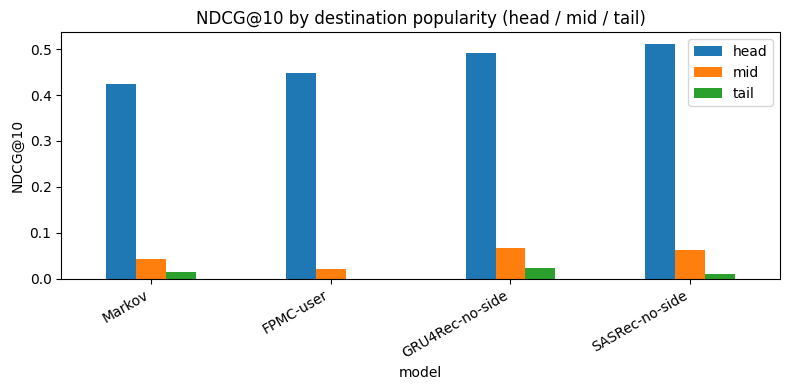

Contribution of each bucket to overall NDCG@10 (bucket score x bucket share of test trips):


,head,mid,tail
model,,,
Markov,0.3655,0.0046,0.0005
FPMC-user,0.3876,0.0023,0.0000
GRU4Rec-no-side,0.4241,0.0071,0.0007
SASRec-no-side,0.4416,0.0066,0.0003


In [ ]:
freq = city_frequency(data)
q50, q90 = np.quantile(freq[freq > 0], [0.5, 0.9])
print(f'train-frequency cut-offs: tail <= {q50:.0f} visits, head >= {q90:.0f} visits')

def pop_group(tgt):
    f = freq[tgt]
    return 'head' if f >= q90 else ('tail' if f <= q50 else 'mid')

POP_ORDER = ['head', 'mid', 'tail']
pop_groups = [pop_group(t) for t in targets]
share = pd.Series(pop_groups).value_counts(normalize=True).reindex(POP_ORDER)
print('share of test targets per bucket:', share.round(3).to_dict())
unseen = np.mean([(t in (0, 1)) or freq[t] == 0 for t in targets])
print(f'test targets never seen in training (unreachable, automatic miss): {unseen:.2%}')

pop_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, pop_groups)
    pop_rows.append({'model': name, **{g: sl[g]['NDCG@10'] for g in POP_ORDER if g in sl}})
pop_df = pd.DataFrame(pop_rows).set_index('model')
display(pop_df.round(4))

pop_df.plot.bar(figsize=(8, 4))
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by destination popularity (head / mid / tail)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

contrib = pop_df.mul(share, axis=1)
print('Contribution of each bucket to overall NDCG@10 (bucket score x bucket share of test trips):')
display(contrib.round(4))


1. Recommendation Quality is Dominated by "Head" Popularity

Notice the massive height of the blue bars compared to the orange and green bars across all models.
*  The Data: For SASRec-no-side, the NDCG@10 is a strong 0.5111 on popular head items, but crashes down to 0.0626 on mid items and 0.0102 on rare tail items.
*  The Reason: Recommendation models naturally thrive on items they see frequently. When a city has plenty of data, the system easily maps out its common travel routes and user associations. When a destination is a rare "tail" item, the models simply don't have enough data patterns to confidently predict it.

2. A Severe Cold-Start / Tail Failure for FPMC-persona

Look closely at the first table's Tail column for FPMC-user: its score drops to an incredibly low 0—drastically worse than the basic, unpersonalized Markov baseline (0.0152).
*  The Reason: FPMC relies on building structured personalized matrix spaces. When it encounters a rare tail city, it severely suffers from the cold-start problem. It tries to personalize data that doesn't exist, overfits completely, and ends up performing worse than a basic Markov chain that just counts raw transitions.

3. The Bottom Table: Where Your Final Score Actually Comes From

The bottom table shows the contribution of each bucket to your final overall NDCG score (calculated by multiplying the score by the percentage share of the test set).
*  The Takeaway: Your final metric is almost entirely decided by the Head items. For instance, out of SASRec's final performance, 0.4416 comes purely from popular cities, while a tiny 0.0003 comes from the tail.
*  Because your test set is so heavily weighted toward popular destinations (86.4%), a model can completely fail at recommending rare cities and still get an outstanding overall score on paper.

## 7. Efficiency -- accuracy vs. cost

`append_result` only persists the fixed metric columns, so `train_secs` / `n_params` are not in `results.csv`. They
come from the per-seed CSVs (mean over the 5 final-fit seeds) where those exist, otherwise from the one-seed refit in
section 4 - the `source` column says which. Markov's `n_params` is the number of stored `(context, next)` counts.

Models were trained for different numbers of epochs (`E_best`) and possibly on different hardware (the original
FPMC runs were CPU, the neural models GPU), so **seconds per epoch** is the fairer cost number than total time.
Treat cross-model time comparisons as indicative only.

,variant,NDCG@10,n_params,train_secs,E_best,secs_per_epoch,source
algorithm,,,,,,,
Markov,Markov,0.3706,1104652,24.50,NaN,NaN,refit seed 1
FPMC,FPMC-user,0.3897,81886464,719.94,2.0,359.9700,per-seed csv
GRU4Rec,GRU4Rec-no-side,0.4296,11067904,548.98,13.0,42.2292,per-seed csv
SASRec,SASRec-no-side,0.4507,11802880,590.56,5.0,118.1120,per-seed csv


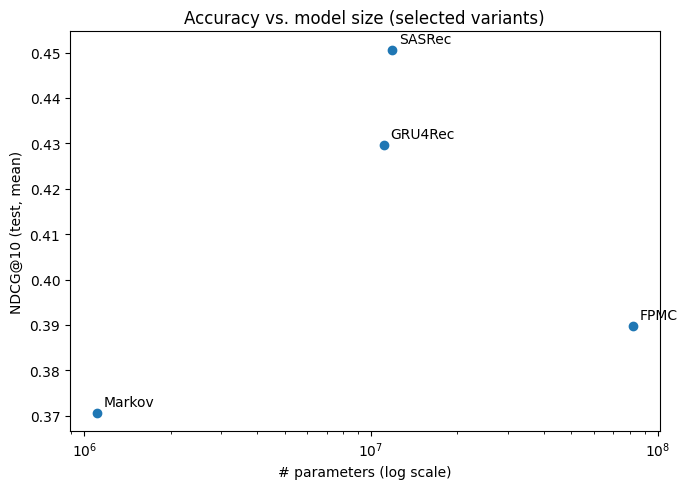

Markov (Markov): max_order=3, mu=41.38, fallback rate on test = 63.6%
(fallback = fraction of test trips whose top-order context was never seen in training - the single number that best explains Markov's ceiling)


In [ ]:
eff = []
for fam in FAMILIES:
    name = HEADLINE[fam]
    if name in per_seed:
        secs, params, src = per_seed[name]['train_secs'].mean(), per_seed[name]['n_params'].iloc[0], 'per-seed csv'
    else:
        secs, params, src = rep_metrics[name]['train_secs'], rep_metrics[name]['n_params'], f'refit seed {REP_SEED}'
    e_best = load_tuning(TAGS[name])['E_best'] if name in TAGS else np.nan
    eff.append({'algorithm': fam, 'variant': name, 'NDCG@10': means.loc[name, 'NDCG@10'], 'n_params': int(params),
                'train_secs': secs, 'E_best': e_best, 'secs_per_epoch': secs / e_best if e_best == e_best else np.nan,
                'source': src})
eff_df = pd.DataFrame(eff).set_index('algorithm')
display(eff_df.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(eff_df['n_params'], eff_df['NDCG@10'])
for fam, row in eff_df.iterrows():
    ax.annotate(f"{fam}", (row['n_params'], row['NDCG@10']), textcoords='offset points', xytext=(5, 5))
ax.set_xscale('log'); ax.set_xlabel('# parameters (log scale)'); ax.set_ylabel('NDCG@10 (test, mean)')
ax.set_title('Accuracy vs. model size (selected variants)'); plt.tight_layout(); plt.show()

mk_name = HEADLINE['Markov']
if 'fallback_rate' in rep_metrics[mk_name]:
    mk_cfg = load_tuning('markov')[mk_name]['best_params']
    print(f"Markov ({mk_name}): max_order={mk_cfg['max_order']}, mu={mk_cfg['mu']:.2f}, "
          f"fallback rate on test = {rep_metrics[mk_name]['fallback_rate']:.1%}")
    print("(fallback = fraction of test trips whose top-order context was never seen in training - "
          "the single number that best explains Markov's ceiling)")

## 8. Bootstrap confidence intervals -- is the *test-set* gap signal or noise?

Multi-seed (section 2.2 / 3) captures **training** variance. Bootstrap captures **evaluation** variance: did we happen
to test on an easy or hard set of trips? We resample test trips with replacement 1000 times. This uses the section-4
ranked lists (one trained model per algorithm), so each CI reflects test-set noise for that one model.

* **Per-model CI** - overlapping CIs do *not* prove a tie, because every model is scored on the *same* trips and their
  errors are correlated;
* **Paired difference** - the same resampled trips score both models of a pair, the proper test of "is A better than B
  on this test set". A 95% CI that excludes 0 means the gap is not test-set noise.

,NDCG@10,boot_mean,ci_low,ci_high
model,,,,
Markov,0.3706,0.3706,0.3675,0.3736
FPMC-user,0.3898,0.3898,0.3868,0.3929
GRU4Rec-no-side,0.4319,0.4319,0.4290,0.4347
SASRec-no-side,0.4485,0.4485,0.4457,0.4514


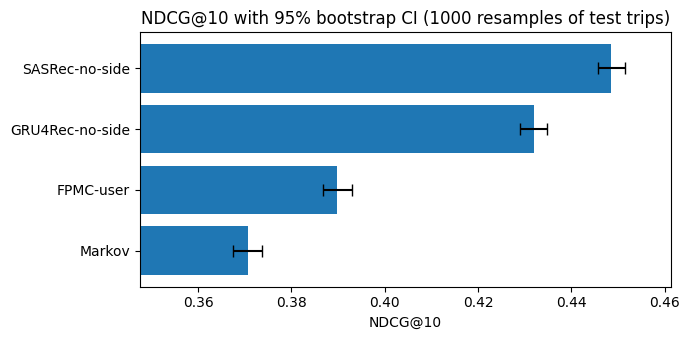

,A,B,NDCG@10 diff (A-B),ci_low,ci_high,excludes 0
0,SASRec-no-side,GRU4Rec-no-side,0.0167,0.0150,0.0183,True
1,GRU4Rec-no-side,FPMC-user,0.0421,0.0400,0.0440,True
2,FPMC-user,Markov,0.0192,0.0174,0.0209,True
3,GRU4Rec-no-side,Markov,0.0613,0.0594,0.0631,True


In [ ]:
N_BOOT = 1000
boot_rows = []
for name, ranked in ranked_rep.items():
    mean, (lo, hi) = bootstrap_ci(ranked, targets, metric='NDCG@10', n_boot=N_BOOT)
    boot_rows.append({'model': name, 'NDCG@10': rep_metrics[name]['NDCG@10'], 'boot_mean': mean, 'ci_low': lo, 'ci_high': hi})
boot_df = pd.DataFrame(boot_rows).set_index('model').sort_values('boot_mean')
display(boot_df.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
yerr = np.vstack([boot_df['boot_mean'] - boot_df['ci_low'], boot_df['ci_high'] - boot_df['boot_mean']])
ax.barh(boot_df.index, boot_df['boot_mean'], xerr=yerr, capsize=4)
ax.set_xlim(boot_df['ci_low'].min() - 0.02, boot_df['ci_high'].max() + 0.01)
ax.set_xlabel('NDCG@10'); ax.set_title(f'NDCG@10 with 95% bootstrap CI ({N_BOOT} resamples of test trips)')
plt.tight_layout(); plt.show()

BOOT_PAIRS = [('SASRec', 'GRU4Rec'), ('GRU4Rec', 'FPMC'), ('FPMC', 'Markov'), ('GRU4Rec', 'Markov')]
pd_rows = []
for a, b in BOOT_PAIRS:
    d, (lo, hi) = paired_bootstrap_diff(ranked_rep[HEADLINE[a]], ranked_rep[HEADLINE[b]], targets, metric='NDCG@10', n_boot=N_BOOT)
    pd_rows.append({'A': HEADLINE[a], 'B': HEADLINE[b], 'NDCG@10 diff (A-B)': d, 'ci_low': lo, 'ci_high': hi,
                    'excludes 0': (lo > 0) or (hi < 0)})
boot_pairs_df = pd.DataFrame(pd_rows)
display(boot_pairs_df.round(4))

**1. The model intervals do not overlap**

- **Finding:** None of the 95% bootstrap intervals overlap. For example, SASRec-no-side's lowest value (0.4457) is above GRU4Rec-no-side's highest (0.4347), and the same holds for every other adjacent pair.
- **Meaning:** The ranking SASRec > GRU4Rec > FPMC > Markov does not depend on which test trips happened to be drawn. The intervals are narrow (about ±0.003 NDCG@10), so test-set sampling noise is small relative to the gaps between models.

**2. Paired difference test**

The paired bootstrap resamples the *same* test trips for both models of a pair, which gives a tighter test than comparing separate intervals.

- **excludes 0 = True** for every pair, so no gap is explained by test-set noise.
- Each difference is estimated precisely (intervals about ±0.002).

**3. Size of each step**

| Comparison | NDCG@10 gain | 95% CI |
|---|---|---|
| Markov → FPMC-user | +0.0192 | [0.0174, 0.0209] |
| FPMC-user → GRU4Rec-no-side | +0.0421 | [0.0400, 0.0440] |
| GRU4Rec-no-side → SASRec-no-side | +0.0167 | [0.0150, 0.0183] |
| Markov → GRU4Rec-no-side (total) | +0.0613 | [0.0594, 0.0631] |

- **Sequence memory is the largest step:** Moving from FPMC-user, which sees only the last city plus a user factor, to GRU4Rec, which uses the whole history, gives the biggest jump (+0.042).
- **Personalisation adds the least:** FPMC-user improves on Markov by about +0.019. The raw user ID is of little use because almost every user appears in only one trip.
- **Attention adds a smaller gain on top of recurrence:** SASRec improves on GRU4Rec by about +0.017.
- **Total:** The best model beats the Markov baseline by about +0.061 NDCG@10.

**Caveat:** The bootstrap measures test-set noise for one re-fitted seed per model. It does not capture training variance, which is reported separately as the ± over five seeds. The figures here (e.g. SASRec 0.4485) come from that single seed and differ slightly from the five-seed means in the results table (SASRec 0.4507, GRU4Rec 0.4296).

## 9. Final discussion and key takeaways

### 9.1 Data-driven findings
The next cell turns the tables above into plain-language statements (so the wording always matches the numbers from
the run). Copy them into the report.

In [ ]:
def verdict(vals):
    # vals: advantage over Markov per bucket in order <=3, 4-5, 6+
    d1, d2, d3 = vals
    if d3 > d1 + 0.005 and d3 >= d2: return 'GROWS with trip length'
    if d3 < d1 - 0.005: return 'SHRINKS with trip length'
    return 'is roughly flat / non-monotonic across trip length'

print('TRIP LENGTH (central hypothesis: long-range memory should pay off on longer trips)')
for name, r in adv.iterrows():
    vals = [r[g] for g in LEN_ORDER]
    print(f"  - {name}: NDCG@10 advantage over {mk} by bucket {({g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)})} -> {verdict(vals)}.")
n_sup = sum(verdict([r[g] for g in LEN_ORDER]).startswith('GROWS') for _, r in adv.iterrows())
print(f"  => hypothesis {'supported' if n_sup == len(adv) else 'NOT (fully) supported'}: the advantage grows with length for "
      f"{n_sup} of {len(adv)} models.\n")

print('DESTINATION POPULARITY')
for name in contrib.index:
    print(f"  - {name}: {contrib.loc[name, 'head'] / contrib.loc[name].sum():.0%} of its NDCG@10 comes from head destinations "
          f"(head = {share['head']:.0%} of test trips); tail NDCG@10 = {pop_df.loc[name, 'tail']:.4f}.")
best_tail = pop_df['tail'].idxmax(); best_mid = pop_df['mid'].idxmax()
print(f"  => best on mid: {best_mid}; best on tail: {best_tail}. "
      f"{'Embedding models beat Markov on the tail.' if best_tail != mk else 'Markov is best on the tail, so the generalisation hypothesis is NOT supported.'}")
print(f"  => {unseen:.1%} of test targets were never seen in training and cannot be predicted by any model.\n")

print('TEST-SET NOISE (paired bootstrap, NDCG@10)')
for _, r in boot_pairs_df.iterrows():
    print(f"  - {r['A']} vs {r['B']}: diff {r['NDCG@10 diff (A-B)']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}] -> "
          f"{'real gap' if r['excludes 0'] else 'NOT distinguishable from 0'}.")

print('\nEFFICIENCY')
for fam, r in eff_df.iterrows():
    tag = fam if fam == r['variant'] else f"{fam} ({r['variant']})"
    print(f"  - {tag}: {r['n_params']:,} params, {r['secs_per_epoch']:.1f} s/epoch, NDCG@10 {r['NDCG@10']:.4f}.")
if 'GRU4Rec' in eff_df.index and 'SASRec' in eff_df.index:
    a, b = eff_df.loc['SASRec'], eff_df.loc['GRU4Rec']
    print(f"  => SASRec vs GRU4Rec: {a['n_params'] / b['n_params']:.1f}x the parameters, "
          f"{a['secs_per_epoch'] / b['secs_per_epoch']:.1f}x the time per epoch, for "
          f"{a['NDCG@10'] - b['NDCG@10']:+.4f} NDCG@10 (hardware may differ - see section 7).")

TRIP LENGTH (central hypothesis: long-range memory should pay off on longer trips)
  - FPMC-user: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  - GRU4Rec-no-side: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  - SASRec-no-side: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  => hypothesis supported: the advantage grows with length for 3 of 3 models.

DESTINATION POPULARITY
  - Markov: 99% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0152.
  - FPMC-user: 99% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0000.
  - GRU4Rec-no-side: 98% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0231.
  - SASRec-no-side: 98% of its NDCG@10 com